1. Load the Customer data sheet in Python. Set churned as y. Remove churned and customer_id
from X.

In [2]:
import numpy as np 
import pandas as pd 


In [3]:
import pandas as pd
df = pd.read_excel('../data/customer_churn_classification.xlsx', engine='openpyxl')
df.head(5)  

,customer_id,age_years,tenure_months,monthly_fee_inr,weekly_usage_hours,support_tickets_6m,late_payments_6m,discount_percent,auto_pay,satisfaction_score,competitor_offer,churned
0,C0001,39,50,800,11.5,3,1,20,1,9,1,0
1,C0002,58,20,1100,16.6,0,0,0,0,9,1,0
2,C0003,43,9,1350,14.6,3,0,0,1,7,0,0
3,C0004,42,40,850,13.5,6,1,5,1,5,0,1
4,C0005,26,44,800,11.8,5,3,5,0,4,0,1


In [4]:
print(list(df.columns))

['customer_id', 'age_years', 'tenure_months', 'monthly_fee_inr', 'weekly_usage_hours', 'support_tickets_6m', 'late_payments_6m', 'discount_percent', 'auto_pay', 'satisfaction_score', 'competitor_offer', 'churned']


In [6]:
X = df.drop(columns=['churned', 'customer_id'], axis=1)
y = df['churned']

In [ ]:


# Train multiple models and compare accuracy
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# ensure dataframe loaded
try:
	df
except NameError:
	df = pd.read_excel('../data/customer_churn_classification.xlsx', engine='openpyxl')

X = df.drop(columns=['churned', 'customer_id'])
X = pd.get_dummies(X, drop_first=True)
y = df['churned']

X_train, X_test, y_train, y_test = train_test_split(
	X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

models = {
	'LogisticRegression': LogisticRegression(max_iter=1000),
	'RandomForest': RandomForestClassifier(n_estimators=100, random_state=42),
	'SVC': SVC(random_state=42),
	'KNN': KNeighborsClassifier(),
	'GradientBoosting': GradientBoostingClassifier(random_state=42),
}

results = {}
for name, model in models.items():
	model.fit(X_train, y_train)
	preds = model.predict(X_test)
	results[name] = accuracy_score(y_test, preds)

results_series = pd.Series(results).sort_values(ascending=False)
print(results_series)

ax = results_series.plot.bar(title='Model Accuracy (test set)', rot=45)
ax.set_ylabel('Accuracy')
plt.tight_layout()
plt.show()

In [7]:
X.head(5)

,age_years,tenure_months,monthly_fee_inr,weekly_usage_hours,support_tickets_6m,late_payments_6m,discount_percent,auto_pay,satisfaction_score,competitor_offer
0,39,50,800,11.5,3,1,20,1,9,1
1,58,20,1100,16.6,0,0,0,0,9,1
2,43,9,1350,14.6,3,0,0,1,7,0
3,42,40,850,13.5,6,1,5,1,5,0
4,26,44,800,11.8,5,3,5,0,4,0


2. Make a stratified 80/20 training and test split. Check how many customers canceled in each
split.

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

y_train_s = pd.Series(y_train)
y_test_s = pd.Series(y_test)

print("--- Training Set ---")
print(y_train_s.value_counts())
print("\nTraining Set Proportions:")
print(y_train_s.value_counts(normalize=True).round(4))

print("\n--- Test Set ---")
print(y_test_s.value_counts())
print("\nTest Set Proportions:")
print(y_test_s.value_counts(normalize=True).round(4))

--- Training Set ---
churned
0    288
1    112
Name: count, dtype: int64

Training Set Proportions:
churned
0    0.72
1    0.28
Name: proportion, dtype: float64

--- Test Set ---
churned
0    72
1    28
Name: count, dtype: int64

Test Set Proportions:
churned
0    0.72
1    0.28
Name: proportion, dtype: float64


In [24]:
results = {}
false_positive = {}
false_negative = {}

3. Train these five models separately: KNN, Gaussian Naive Bayes, Decision Tree, Random
Forest, and Logistic Regression.

In [25]:
#KNN Classifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

results['KNN'] = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
knn_confusion = confusion_matrix(y_test, y_pred)
knn_false_positive = knn_confusion[1, 0]
knn_false_negative = knn_confusion[0, 1]
false_positive['KNN'] = knn_false_positive
false_negative['KNN'] = knn_false_negative

Accuracy: 0.71

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.88      0.81        72
           1       0.47      0.29      0.36        28

    accuracy                           0.71       100
   macro avg       0.61      0.58      0.58       100
weighted avg       0.68      0.71      0.68       100


Confusion Matrix:
[[63  9]
 [20  8]]


In [26]:
#gaussianNB Classifier
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred_gnb = gnb.predict(X_test) 
results['GaussianNB'] = accuracy_score(y_test, y_pred_gnb)   

print("Accuracy:", accuracy_score(y_test, y_pred_gnb))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_gnb))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gnb))
gnb_confusion = confusion_matrix(y_test, y_pred_gnb)
false_positive['GaussianNB'] = gnb_confusion[1, 0]
false_negative['GaussianNB'] = gnb_confusion[0, 1]


Accuracy: 0.78

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.83      0.85        72
           1       0.60      0.64      0.62        28

    accuracy                           0.78       100
   macro avg       0.73      0.74      0.73       100
weighted avg       0.79      0.78      0.78       100


Confusion Matrix:
[[60 12]
 [10 18]]


In [27]:
#Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier
dtc = DecisionTreeClassifier(max_depth=8, random_state=42)
dtc.fit(X_train, y_train)
y_pred_dtc = dtc.predict(X_test)
results['DecisionTree'] = accuracy_score(y_test, y_pred_dtc)

print("Accuracy:", accuracy_score(y_test, y_pred_dtc))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dtc))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dtc))
dtc_confusion = confusion_matrix(y_test, y_pred_dtc)
false_positive['DecisionTree'] = dtc_confusion[1, 0]
false_negative['DecisionTree'] = dtc_confusion[0, 1]

Accuracy: 0.77

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.83      0.84        72
           1       0.59      0.61      0.60        28

    accuracy                           0.77       100
   macro avg       0.72      0.72      0.72       100
weighted avg       0.77      0.77      0.77       100


Confusion Matrix:
[[60 12]
 [11 17]]


In [28]:
#Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier
rfc = RandomForestClassifier(n_estimators=100, random_state=42)
rfc.fit(X_train, y_train)
y_pred_rfc = rfc.predict(X_test)
results['RandomForest'] = accuracy_score(y_test, y_pred_rfc)
print("Accuracy:", accuracy_score(y_test, y_pred_rfc))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rfc))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rfc))
rfc_confusion = confusion_matrix(y_test, y_pred_rfc)
false_positive['RandomForest'] = rfc_confusion[1, 0]
false_negative['RandomForest'] = rfc_confusion[0, 1]

Accuracy: 0.86

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.90      0.90        72
           1       0.75      0.75      0.75        28

    accuracy                           0.86       100
   macro avg       0.83      0.83      0.83       100
weighted avg       0.86      0.86      0.86       100


Confusion Matrix:
[[65  7]
 [ 7 21]]


In [33]:
#logistic regression
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train, y_train)
y_pred_logreg = logreg.predict(X_test)
results['LogisticRegression'] = accuracy_score(y_test, y_pred_logreg)
print("Accuracy:", accuracy_score(y_test, y_pred_logreg))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_logreg))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logreg))
logreg_confusion = confusion_matrix(y_test, y_pred_logreg)
false_positive['LogisticRegression'] = logreg_confusion[1, 0]
false_negative['LogisticRegression'] = logreg_confusion[0, 1]

Accuracy: 0.83

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.86      0.88        72
           1       0.68      0.75      0.71        28

    accuracy                           0.83       100
   macro avg       0.79      0.81      0.80       100
weighted avg       0.84      0.83      0.83       100


Confusion Matrix:
[[62 10]
 [ 7 21]]


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_streng

4 Use a StandardScaler pipeline for KNN and Logistic Regression. Fit the scaler using training
data only

In [29]:
#standardize the data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn_scaled = KNeighborsClassifier(n_neighbors=5)
knn_scaled.fit(X_train_scaled, y_train)
y_pred_scaled = knn_scaled.predict(X_test_scaled)
results['KNN_Scaled'] = accuracy_score(y_test, y_pred_scaled)
print("Accuracy:", accuracy_score(y_test, y_pred_scaled))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_scaled))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_scaled))
knn_scaled_confusion = confusion_matrix(y_test, y_pred_scaled)
false_positive['KNN_Scaled'] = knn_scaled_confusion[1, 0]
false_negative['KNN_Scaled'] = knn_scaled_confusion[0, 1]


Accuracy: 0.75

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.86      0.83        72
           1       0.57      0.46      0.51        28

    accuracy                           0.75       100
   macro avg       0.69      0.66      0.67       100
weighted avg       0.74      0.75      0.74       100


Confusion Matrix:
[[62 10]
 [15 13]]


In [31]:
logreg_scaled = LogisticRegression(max_iter=1000, random_state=42)
logreg_scaled.fit(X_train_scaled, y_train)
y_pred_logreg_scaled = logreg_scaled.predict(X_test_scaled)
results['LogisticRegression_Scaled'] = accuracy_score(y_test, y_pred_logreg_scaled)
print("Accuracy:", accuracy_score(y_test, y_pred_logreg_scaled))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_logreg_scaled))
print("\nConfusion Matrix:")

print(confusion_matrix(y_test, y_pred_logreg_scaled))
logreg_scaled_confusion = confusion_matrix(y_test, y_pred_logreg_scaled)
false_positive['LogisticRegression_Scaled'] = logreg_scaled_confusion[1, 0]
false_negative['LogisticRegression_Scaled'] = logreg_scaled_confusion[0, 1]


Accuracy: 0.82

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.85      0.87        72
           1       0.66      0.75      0.70        28

    accuracy                           0.82       100
   macro avg       0.78      0.80      0.79       100
weighted avg       0.83      0.82      0.82       100


Confusion Matrix:
[[61 11]
 [ 7 21]]


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_streng

Compare the models: Which catches the most customers who cancel? Which produces the
fewest false alarms? Would you choose the same model for both goals?

In [34]:
print("\n--- Summary of Model Accuracies ---")
for model, accuracy in results.items():
    print(f"{model} : {accuracy:.4f}")


--- Summary of Model Accuracies ---
KNN : 0.7100
GaussianNB : 0.7800
DecisionTree : 0.7700
RandomForest : 0.8600
KNN_Scaled : 0.7500
LogisticRegression_Scaled : 0.8200
LogisticRegression : 0.8300


RandomForest                 0.86
LogisticRegression           0.83
LogisticRegression_Scaled    0.82
GaussianNB                   0.78
DecisionTree                 0.77
KNN_Scaled                   0.75
KNN                          0.71
dtype: float64


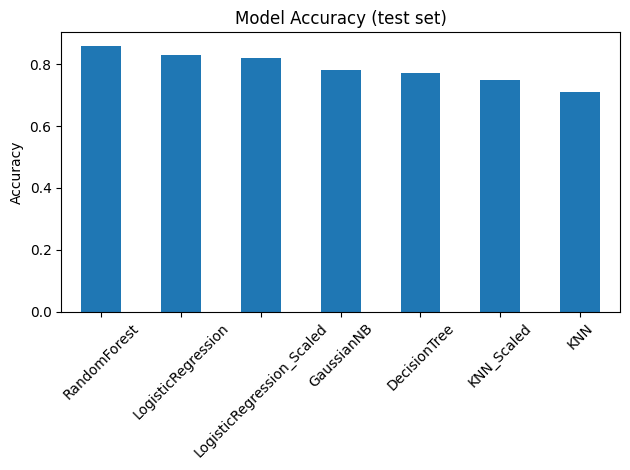

In [35]:
import matplotlib.pyplot as plt
results_series = pd.Series(results).sort_values(ascending=False)
print(results_series)

ax = results_series.plot.bar(title='Model Accuracy (test set)', rot=45)
ax.set_ylabel('Accuracy')
plt.tight_layout()
plt.show()

Lowest False Positive: LogisticRegression ( 7 )
Lowest False Negative: RandomForest ( 7 )

Error comparison table:
                       Model  FalsePositive  FalseNegative  TotalErrors
6               RandomForest              7              7           14
4         LogisticRegression              7             10           17
5  LogisticRegression_Scaled              7             11           18
1                 GaussianNB             10             12           22
0               DecisionTree             11             12           23
3                 KNN_Scaled             15             10           25
2                        KNN             20              9           29


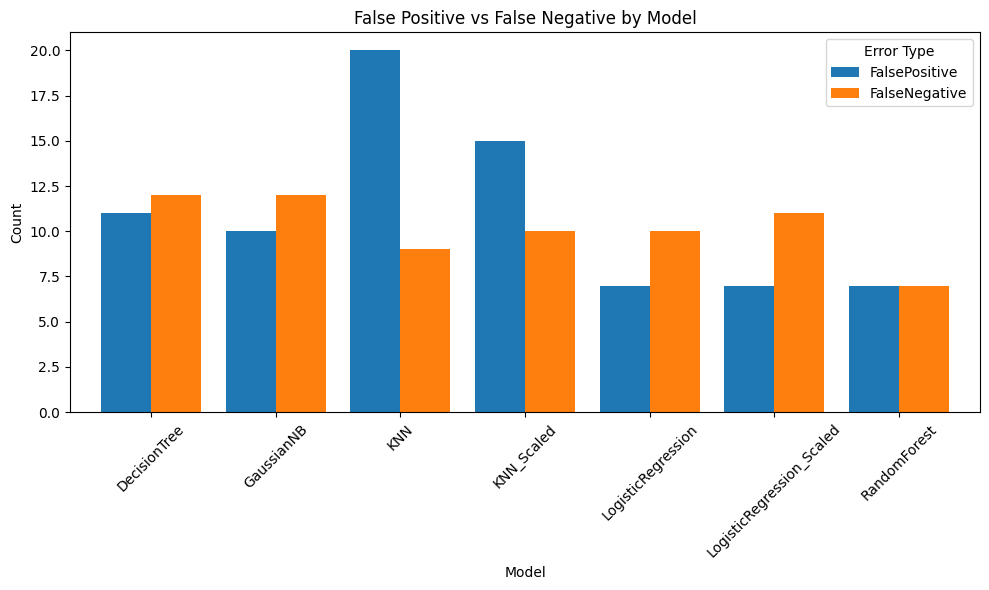

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

fp_series = pd.Series(false_positive).sort_index()
fn_series = pd.Series(false_negative).sort_index()
comparison_df = pd.DataFrame({
    'Model': fp_series.index,
    'FalsePositive': fp_series.values,
    'FalseNegative': fn_series.reindex(fp_series.index).values,
})
comparison_df['TotalErrors'] = comparison_df['FalsePositive'] + comparison_df['FalseNegative']

lowest_fp_model = comparison_df.loc[comparison_df['FalsePositive'].idxmin(), 'Model']
lowest_fn_model = comparison_df.loc[comparison_df['FalseNegative'].idxmin(), 'Model']

print("Lowest False Positive:", lowest_fp_model, "(", comparison_df['FalsePositive'].min(), ")")
print("Lowest False Negative:", lowest_fn_model, "(", comparison_df['FalseNegative'].min(), ")")
print("\nError comparison table:")
print(comparison_df[['Model', 'FalsePositive', 'FalseNegative', 'TotalErrors']].sort_values('TotalErrors'))

ax = comparison_df.plot(
    x='Model',
    kind='bar',
    y=['FalsePositive', 'FalseNegative'],
    figsize=(10, 6),
    width=0.8,
    title='False Positive vs False Negative by Model'
)
ax.set_ylabel('Count')
ax.set_xlabel('Model')
ax.legend(title='Error Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


AFter analysing Accuracy and false positive and false negative choosed "Random forest perform best among models."

KNN accuracy across different K values:

    K  Accuracy
0   1      0.60
1   3      0.63
2   5      0.71
3   7      0.70
4   9      0.69
5  11      0.70
6  13      0.70
7  15      0.72
8  17      0.68
9  19      0.69

Best K from test set: 15


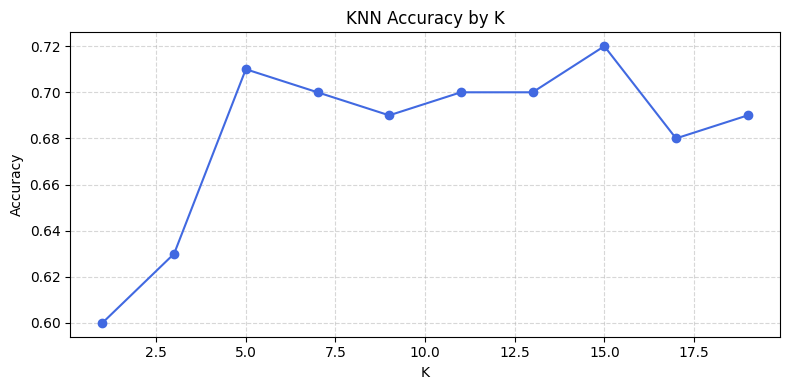


Small decision tree learned by the model:

Tree depth: 3
Number of leaves: 8


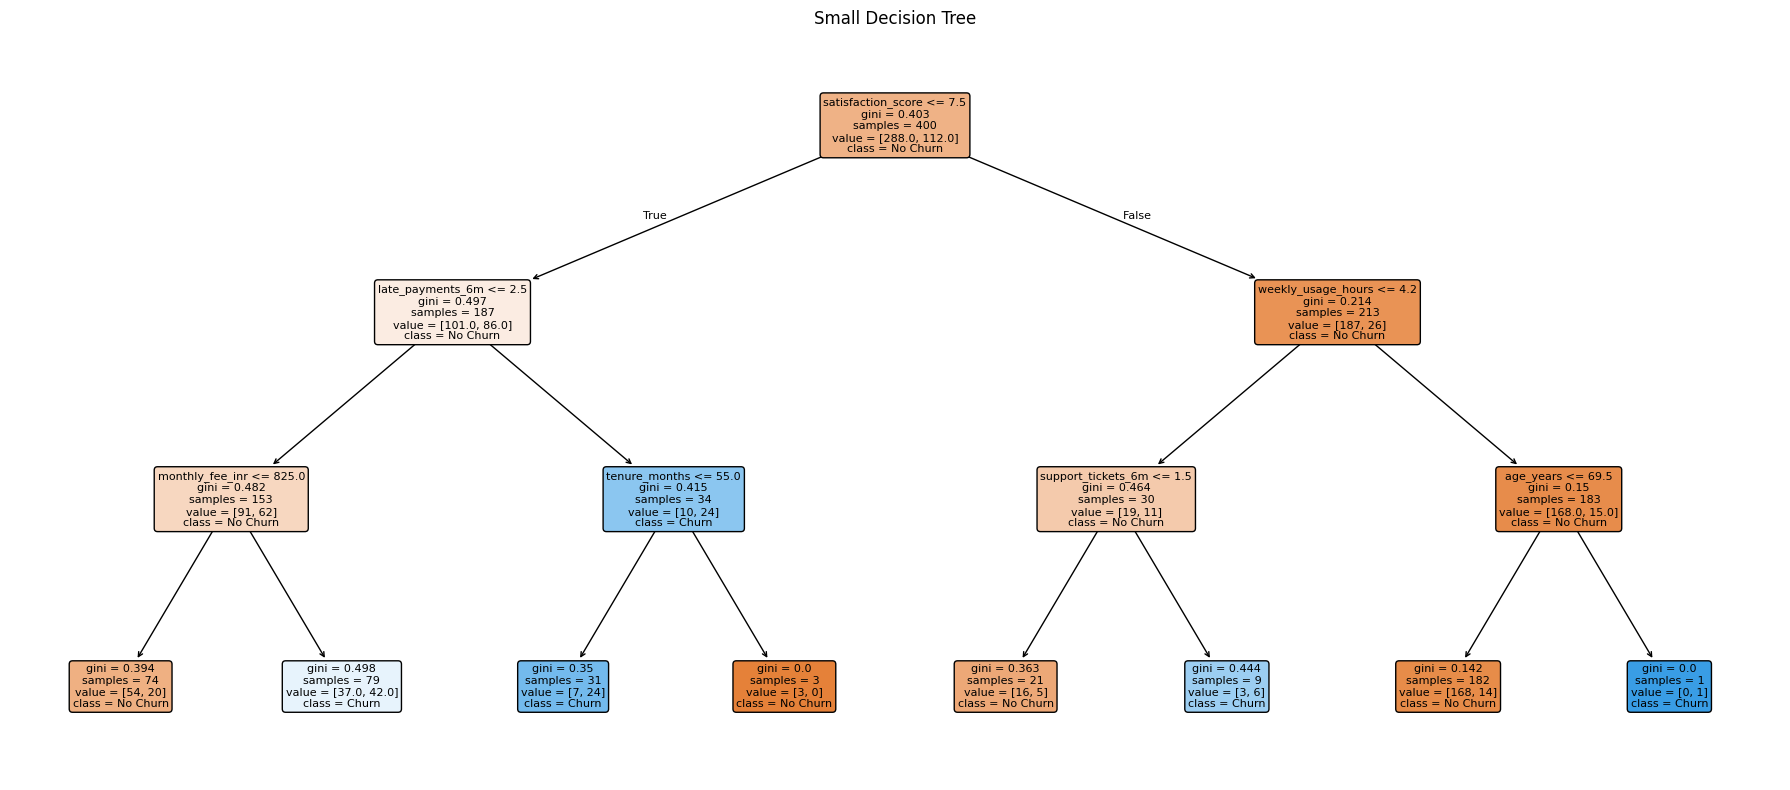


Top 10 features from Random Forest:

              feature  importance
3  weekly_usage_hours    0.186087
8  satisfaction_score    0.154718
1       tenure_months    0.126780
2     monthly_fee_inr    0.117799
0           age_years    0.111471
4  support_tickets_6m    0.101898
5    late_payments_6m    0.086089
6    discount_percent    0.054471
9    competitor_offer    0.039025
7            auto_pay    0.021660


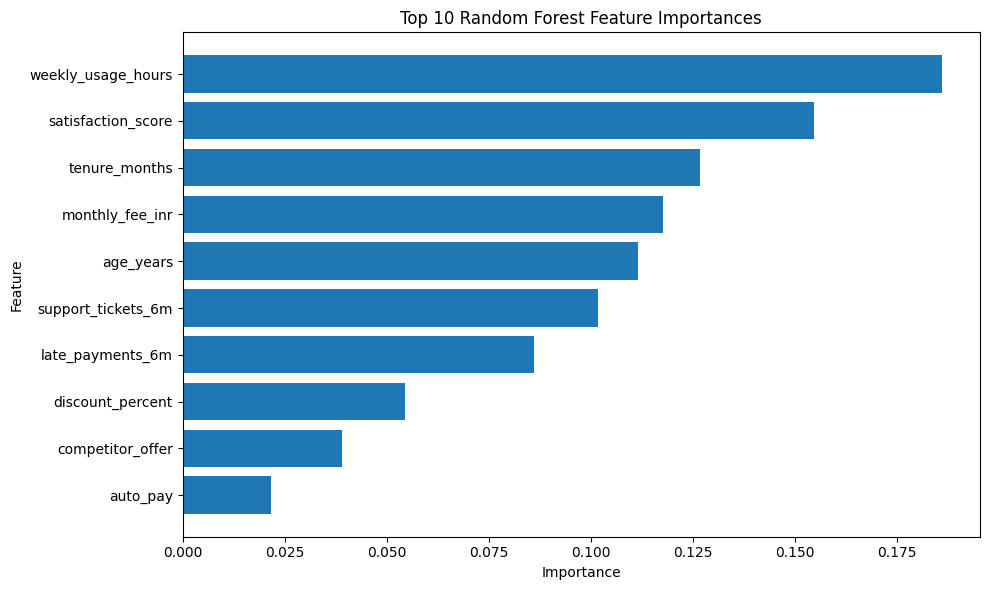


Logistic Regression coefficients (largest magnitude first):

              feature      coef
9    competitor_offer  1.299118
7            auto_pay -0.646693
5    late_payments_6m  0.644743
4  support_tickets_6m  0.507418
8  satisfaction_score -0.273786
3  weekly_usage_hours -0.161310
1       tenure_months -0.029534
0           age_years  0.009970
6    discount_percent -0.005201
2     monthly_fee_inr  0.001505

Most positive coefficients:
              feature      coef
9    competitor_offer  1.299118
5    late_payments_6m  0.644743
4  support_tickets_6m  0.507418
0           age_years  0.009970
2     monthly_fee_inr  0.001505
6    discount_percent -0.005201
1       tenure_months -0.029534
3  weekly_usage_hours -0.161310
8  satisfaction_score -0.273786
7            auto_pay -0.646693

Most negative coefficients:
              feature      coef
7            auto_pay -0.646693
8  satisfaction_score -0.273786
3  weekly_usage_hours -0.161310
1       tenure_months -0.029534
6    discount_pe

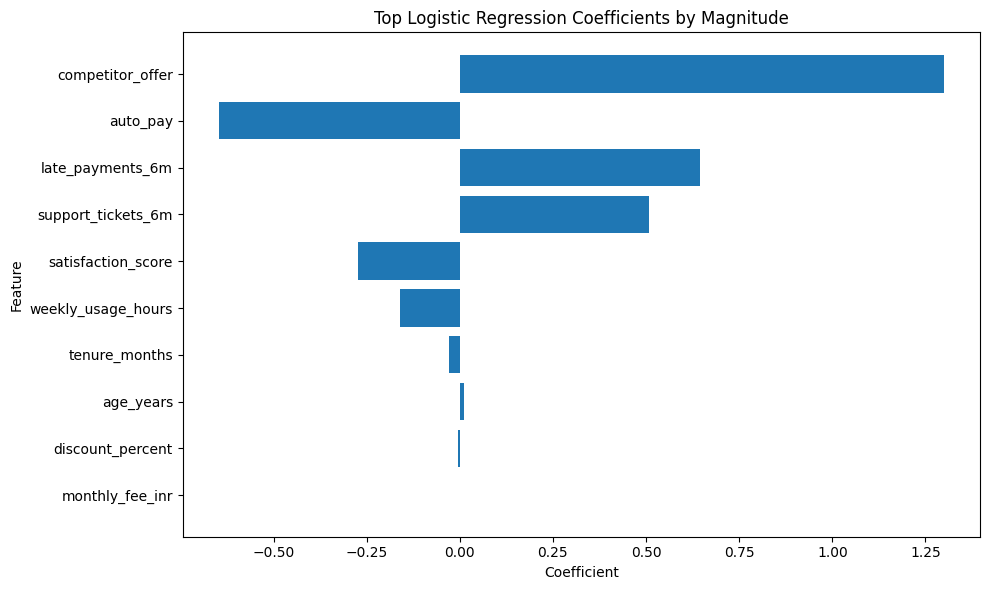

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Compare K values for KNN
print("KNN accuracy across different K values:\n")
k_values = list(range(1, 21, 2))
knn_scores = []
for k in k_values:
    knn_model = KNeighborsClassifier(n_neighbors=k)
    knn_model.fit(X_train, y_train)
    pred_k = knn_model.predict(X_test)
    score = accuracy_score(y_test, pred_k)
    knn_scores.append(score)

k_results = pd.DataFrame({"K": k_values, "Accuracy": knn_scores})
print(k_results)
print(f"\nBest K from test set: {k_results.loc[k_results['Accuracy'].idxmax(), 'K']}")

plt.figure(figsize=(8, 4))
plt.plot(k_results['K'], k_results['Accuracy'], marker='o', color='royalblue')
plt.title('KNN Accuracy by K')
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Small decision tree inspection
print("\nSmall decision tree learned by the model:\n")
dt_small = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_small.fit(X_train, y_train)
print("Tree depth:", dt_small.get_depth())
print("Number of leaves:", dt_small.get_n_leaves())
plt.figure(figsize=(18, 8))
plot_tree(
    dt_small,
    feature_names=X.columns,
    class_names=['No Churn', 'Churn'],
    filled=True,
    rounded=True,
    fontsize=8,
)
plt.title('Small Decision Tree')
plt.tight_layout()
plt.show()

# Forest feature importance
print("\nTop 10 features from Random Forest:\n")
rf_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rfc.feature_importances_
}).sort_values('importance', ascending=False)
print(rf_importance.head(10))

plt.figure(figsize=(10, 6))
plt.barh(rf_importance.head(10)['feature'][::-1], rf_importance.head(10)['importance'][::-1])
plt.title('Top 10 Random Forest Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Logistic regression coefficients
print("\nLogistic Regression coefficients (largest magnitude first):\n")
logreg_coef = pd.DataFrame({
    'feature': X.columns,
    'coef': logreg.coef_[0]
})
logreg_coef['abs_coef'] = logreg_coef['coef'].abs()
print(logreg_coef.sort_values('abs_coef', ascending=False).head(10)[['feature', 'coef']])

print("\nMost positive coefficients:")
print(logreg_coef.sort_values('coef', ascending=False).head(10)[['feature', 'coef']])
print("\nMost negative coefficients:")
print(logreg_coef.sort_values('coef').head(10)[['feature', 'coef']])

coef_top = logreg_coef.sort_values('abs_coef', ascending=False).head(10)
plt.figure(figsize=(10, 6))
plt.barh(coef_top['feature'][::-1], coef_top['coef'][::-1])
plt.title('Top Logistic Regression Coefficients by Magnitude')
plt.xlabel('Coefficient')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


After checking K-NN accuracy whan K value is 15
decion tree depth for 3
random forest top important features
Logestic regression co-efficeient.



8.Write a short recommendation explaining which model you would use to identify customers
for a retention campaign.

After comparing allthe model Choose Random forest as best model becuase accuracy is high and false case is less compared to others.